# 🏨 Hotel Booking Analysis

## Project Overview

This project analyzes a hotel booking dataset containing 119,390 booking records to understand booking patterns and cancellation behavior.

The analysis focuses on factors such as hotel type, lead time, deposit type, market segment, customer type, monthly booking patterns, and previous guest history.

The project includes data cleaning, missing value handling, exploratory data analysis (EDA), and data visualization using Python, Pandas, Matplotlib, and Seaborn.

The main objective is to identify important patterns in hotel bookings and understand the factors associated with booking cancellations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/paragchintanwar/hotel-booking-analysis/hotel_bookings.csv


In [3]:
import pandas as pd

df = pd.read_csv('/kaggle/input/datasets/paragchintanwar/hotel-booking-analysis/hotel_bookings.csv')

df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [5]:
missing_values = df.isnull().sum().sort_values(ascending=False)

missing_values[missing_values > 0]

company     112593
agent        16340
country        488
children         4
dtype: int64

In [6]:
df['company'] = df['company'].fillna(0)
df['agent'] = df['agent'].fillna(0)
df['country'] = df['country'].fillna('Unknown')
df['children'] = df['children'].fillna(0)

In [7]:
df.isnull().sum().sum()

np.int64(0)

In [8]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103886,0.007949,0.031912,0.087118,0.137097,0.221124,74.828319,10.775157,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398555,0.097436,0.175767,0.844336,1.497437,0.652306,107.141953,53.943884,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.000000,0.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,152.000000,0.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [9]:
df['is_canceled'].value_counts()

is_canceled
0    75166
1    44224
Name: count, dtype: int64

In [10]:
df['is_canceled'].value_counts(normalize=True) * 100

is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64

In [11]:
df.groupby('hotel')['is_canceled'].mean() * 100

hotel
City Hotel      41.726963
Resort Hotel    27.763355
Name: is_canceled, dtype: float64

In [12]:
df.groupby('is_canceled')['lead_time'].mean()

is_canceled
0     79.984687
1    144.848815
Name: lead_time, dtype: float64

In [13]:
df.groupby('deposit_type')['is_canceled'].mean() * 100

deposit_type
No Deposit    28.377022
Non Refund    99.362446
Refundable    22.222222
Name: is_canceled, dtype: float64

In [14]:
df.groupby('market_segment')['is_canceled'].mean() * 100

market_segment
Aviation          21.940928
Complementary     13.055182
Corporate         18.734655
Direct            15.341901
Groups            61.062036
Offline TA/TO     34.316033
Online TA         36.721143
Undefined        100.000000
Name: is_canceled, dtype: float64

In [15]:
df.groupby('customer_type')['is_canceled'].mean() * 100

customer_type
Contract           30.961727
Group              10.225303
Transient          40.746320
Transient-Party    25.429868
Name: is_canceled, dtype: float64

In [16]:
df.groupby('previous_cancellations')['is_canceled'].mean() * 100

previous_cancellations
0      33.906081
1      94.430673
2      32.758621
3      30.769231
4      22.580645
5      10.526316
6      31.818182
11     28.571429
13     91.666667
14    100.000000
19    100.000000
21    100.000000
24    100.000000
25    100.000000
26    100.000000
Name: is_canceled, dtype: float64

In [17]:
df.groupby('distribution_channel')['is_canceled'].mean() * 100

distribution_channel
Corporate    22.075783
Direct       17.459884
GDS          19.170984
TA/TO        41.025851
Undefined    80.000000
Name: is_canceled, dtype: float64

In [18]:
df.groupby('arrival_date_month')['is_canceled'].mean() * 100

arrival_date_month
April        40.797186
August       37.753117
December     34.970501
February     33.415964
January      30.477315
July         37.453598
June         41.457172
March        32.152338
May          39.665847
November     31.233441
October      38.046595
September    39.170156
Name: is_canceled, dtype: float64

In [19]:

    df.groupby(['arrival_date_month', 'hotel'])['is_canceled'].mean() * 100

arrival_date_month  hotel       
April               City Hotel      46.323529
                    Resort Hotel    29.343308
August              City Hotel      40.097963
                    Resort Hotel    33.449121
December            City Hotel      42.110358
                    Resort Hotel    23.829305
February            City Hotel      38.288016
                    Resort Hotel    25.620367
January             City Hotel      39.668094
                    Resort Hotel    14.819881
July                City Hotel      40.875371
                    Resort Hotel    31.401706
June                City Hotel      44.692171
                    Resort Hotel    33.070608
March               City Hotel      36.946423
                    Resort Hotel    22.871703
May                 City Hotel      44.375607
                    Resort Hotel    28.772127
November            City Hotel      38.122561
                    Resort Hotel    18.916701
October             City Hotel      42.971729
 

In [20]:
df['total_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

In [21]:
df.groupby('is_canceled')['total_stay'].mean()

is_canceled
0    3.393023
1    3.487179
Name: total_stay, dtype: float64

In [22]:
df.groupby('is_canceled')['adr'].mean()

is_canceled
0     99.987693
1    104.964333
Name: adr, dtype: float64

In [23]:
df.groupby('is_canceled')['total_of_special_requests'].mean()

is_canceled
0    0.714060
1    0.328826
Name: total_of_special_requests, dtype: float64

In [24]:
df.groupby('is_canceled')['previous_bookings_not_canceled'].mean()

is_canceled
0    0.202977
1    0.025122
Name: previous_bookings_not_canceled, dtype: float64

In [25]:
df.groupby('is_repeated_guest')['is_canceled'].mean() * 100

is_repeated_guest
0    37.785084
1    14.488189
Name: is_canceled, dtype: float64

In [26]:
df.groupby('is_canceled')['booking_changes'].mean()

is_canceled
0    0.293364
1    0.098340
Name: booking_changes, dtype: float64

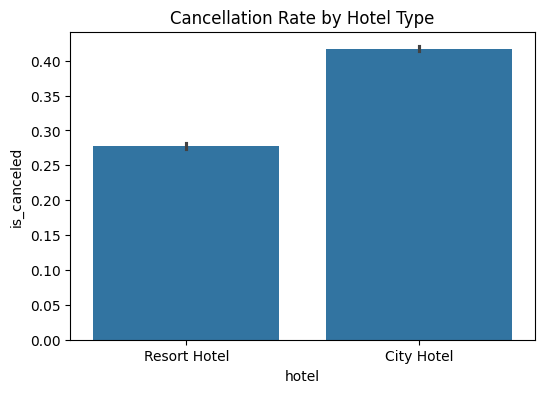

In [27]:
plt.figure(figsize=(6,4))

sns.barplot(x='hotel', y='is_canceled', data=df)

plt.title('Cancellation Rate by Hotel Type')

plt.show()

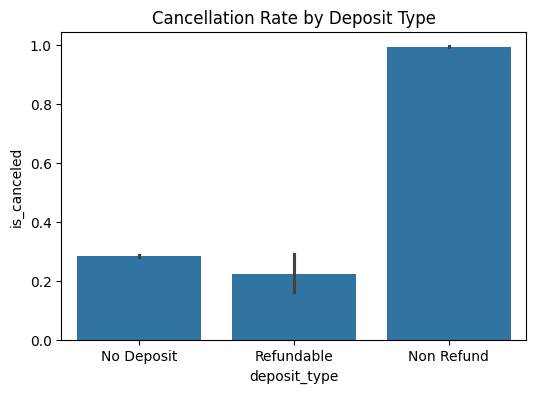

In [28]:
plt.figure(figsize=(6,4))

sns.barplot(x='deposit_type', y='is_canceled', data=df)

plt.title('Cancellation Rate by Deposit Type')

plt.show()

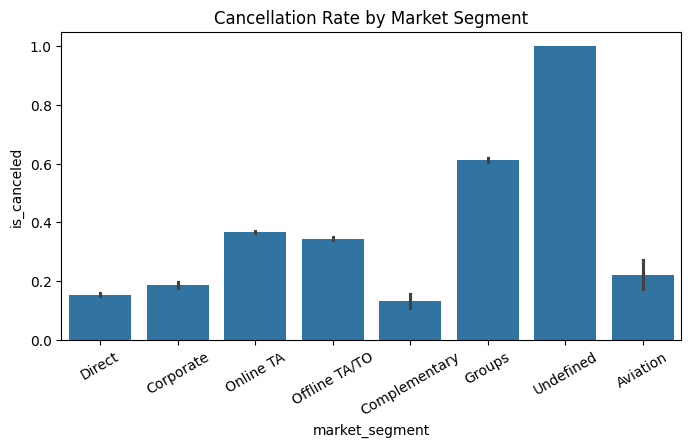

In [29]:
plt.figure(figsize=(8,4))

sns.barplot(x='market_segment', y='is_canceled', data=df)

plt.title('Cancellation Rate by Market Segment')

plt.xticks(rotation=30)

plt.show()

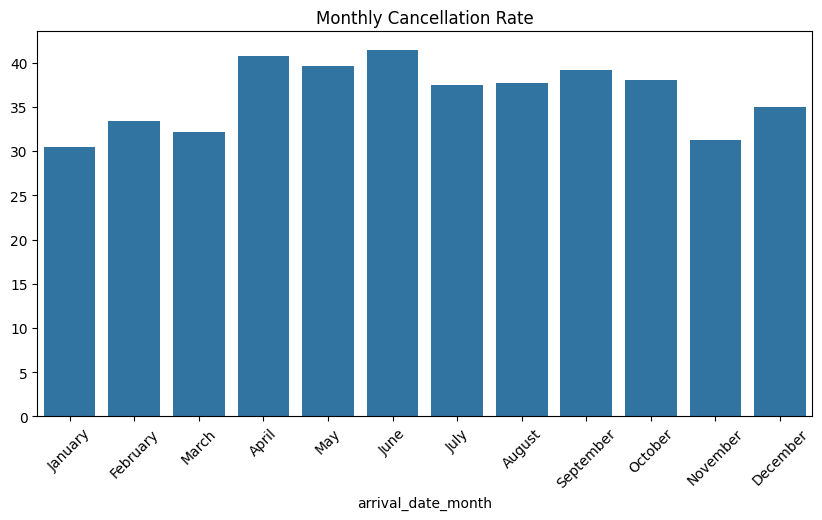

In [30]:
months = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']

data = df.groupby('arrival_date_month')['is_canceled'].mean().reindex(months) * 100

plt.figure(figsize=(10,5))

sns.barplot(x=data.index, y=data.values)

plt.title('Monthly Cancellation Rate')

plt.xticks(rotation=45)

plt.show()

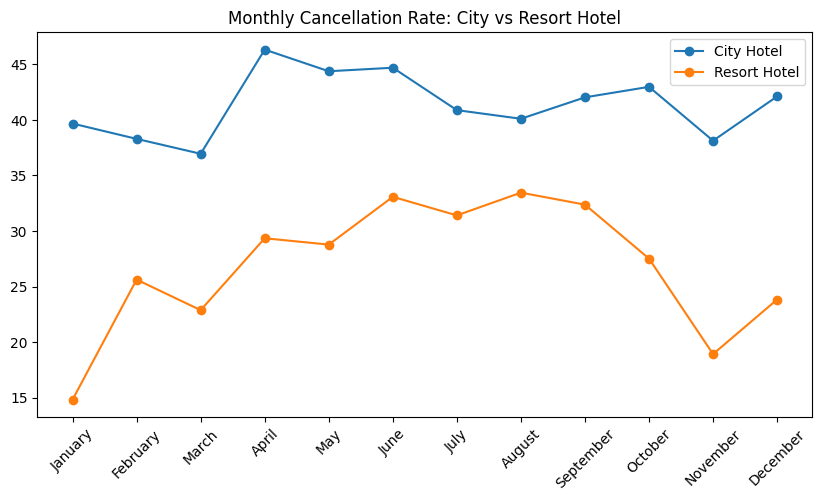

In [31]:
months = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']

data = df.groupby(['arrival_date_month', 'hotel'])['is_canceled'].mean().unstack().reindex(months) * 100

plt.figure(figsize=(10,5))

plt.plot(data.index, data['City Hotel'], marker='o', label='City Hotel')
plt.plot(data.index, data['Resort Hotel'], marker='o', label='Resort Hotel')

plt.title('Monthly Cancellation Rate: City vs Resort Hotel')

plt.xticks(rotation=45)
plt.legend()

plt.show()

## Key Insights

- Overall booking cancellation rate was 37.04%.
- City Hotel had a higher cancellation rate of 41.73% compared to Resort Hotel at 27.76%.
- Canceled bookings had a higher average lead time of 144.85 days.
- Non Refund bookings had a very high cancellation rate of 99.36% in this dataset.
- Repeated guests had a lower cancellation rate of 14.49% compared to 37.79% for non-repeated guests.
- Cancellation rates varied across different market segments and months.

## Conclusion

This analysis helped to understand hotel booking and cancellation patterns.

The results show differences in cancellation rates based on hotel type, lead time, deposit type, market segment, and guest history.

These insights can help hotels better understand booking patterns and identify areas where cancellations are more common.